# 01 · Phân tích khám phá dữ liệu (EDA)

Notebook đọc `HI-Small_Trans.csv`, mô tả dữ liệu, chốt cách chia dev / test / đuôi, tiền xử lý tập giao dịch cho đồ thị và tính baseline cấp giao dịch. Mọi bảng ghi vào `reports/tables/`, mọi hình vào `reports/figures/`, dữ liệu trung gian vào `data/processed/`.

| Mục | Nội dung | Đầu ra chính |
|---|---|---|
| 1 | Đọc dữ liệu, kiểm tra mã ngân hàng và thứ tự dòng | `eda_bank_codes.csv` |
| 2 | Quy mô, mất cân bằng lớp | `eda_scale.csv`, `eda_class_balance.csv` |
| 3 | Tỷ lệ rửa tiền theo định dạng, tiền tệ; giao dịch khác tiền tệ | `eda_rate_by_*.csv`, `eda_cross_currency.csv` |
| 4 | Số tiền quy USD, số tiền tròn | `fx_rates.csv`, `eda_amount_summary.csv` |
| 5 | Hoạt động theo thời gian, đuôi dữ liệu, chia dev / test | `analysis_period.json`, `eda_segments.csv` |
| 6 | Self-loop, các kiểu rửa tiền trong `Patterns.txt` | `eda_typologies.csv`, `eda_pattern_coverage.csv`, `eda_attempts_by_segment.csv` |
| 7 | Tiền xử lý cho đồ thị | `hi_small_graph_transactions.parquet`, `hi_small_removed_transactions.parquet` |
| 8 | Baseline cấp giao dịch | `eda_transaction_baselines.csv` |
| 9 | Bảng số liệu chính | `eda_key_numbers.csv` |

## 1. Đọc dữ liệu

In [1]:
from collections import defaultdict, deque
from pathlib import Path
import csv
import json
import os
import re
import tempfile

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


KAGGLE_INPUT = Path("/kaggle/input")
KAGGLE_WORKING = Path("/kaggle/working")
HERE = Path.cwd()


def project_root():
    """Thư mục ghi data/processed và reports."""
    if os.environ.get("HI_SMALL_ROOT"):
        return Path(os.environ["HI_SMALL_ROOT"]).expanduser()
    if KAGGLE_WORKING.is_dir():
        return KAGGLE_WORKING
    if HERE.name == "Notebook":                  # chạy trong repo: Notebook/ nằm trong thư mục dự án
        return HERE.parent
    if (HERE / "IBM_HI_Small_EDA").is_dir():     # notebook đặt cạnh thư mục kết quả
        return HERE / "IBM_HI_Small_EDA"
    return HERE


ROOT = project_root().resolve()
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"


def data_file(env_name, name, required=True):
    """Đường dẫn trong biến môi trường env_name; nếu không có thì tìm ở các chỗ quen thuộc."""
    configured = os.environ.get(env_name)
    if configured:
        path = Path(configured).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f"{env_name} = {path} không phải là file.")
        return path.resolve()
    folders = [ROOT / "data" / "raw", ROOT, ROOT.parent, HERE, HERE.parent]
    # Giải nén Kaggle đôi khi tạo thư mục trùng tên file (…/HI-Small_Trans.csv/HI-Small_Trans.csv).
    candidates = [f / name for f in folders] + [f / name / name for f in folders]
    if KAGGLE_INPUT.is_dir():
        candidates.extend(KAGGLE_INPUT.rglob(name))
    found = sorted({p.resolve() for p in candidates if p.is_file()})
    if len(found) > 1:
        raise ValueError(f"Tìm thấy nhiều bản {name}: {found}. Đặt biến môi trường {env_name}.")
    if found:
        return found[0]
    if required:
        raise FileNotFoundError(
            f"Không tìm thấy {name}. Đặt file vào {ROOT / 'data' / 'raw'} hoặc đặt biến môi trường {env_name}.")
    return None


csv_path = data_file("HI_SMALL_TRANS", "HI-Small_Trans.csv")
patterns_path = data_file("HI_SMALL_PATTERNS", "HI-Small_Patterns.txt", required=False)

# The duplicate Account headers are named by position. IDs stay as strings.
RAW_HEADER = [
    "Timestamp", "From Bank", "Account", "To Bank", "Account", "Amount Received",
    "Receiving Currency", "Amount Paid", "Payment Currency", "Payment Format", "Is Laundering",
]
RAW_COLUMNS = [
    "timestamp", "from_bank", "from_acct", "to_bank", "to_acct", "amt_received",
    "recv_ccy", "amt_paid", "pay_ccy", "payment_format", "is_laundering",
]
TIMESTAMP_FORMAT = "%Y/%m/%d %H:%M"

with csv_path.open(encoding="utf-8-sig", newline="") as stream:
    header = next(csv.reader(stream), None)
if header != RAW_HEADER:
    raise ValueError(f"Expected the original 11-column IBM HI-Small header. Found: {header}")

# Store intermediate data in a temporary DuckDB database.
if "db" in globals():
    db.close()
scratch_db = tempfile.TemporaryDirectory(prefix="hi_small_eda_")
db = duckdb.connect(str(Path(scratch_db.name) / "eda.duckdb"))
db.execute("SET threads = 4")
db.execute("SET memory_limit = '3GB'")
db.execute("SET preserve_insertion_order = true")   # txn_id = thứ tự dòng trong file

schema = "{" + ", ".join(f"'{col}': 'VARCHAR'" for col in RAW_COLUMNS) + "}"
# Mã ngân hàng: giữ chuỗi gốc (from_bank, to_bank) và thêm bản số (from_bank_id, to_bank_id).
# Khóa tài khoản src/dst dùng bản số, nên "010_8000ABC" và "10_8000ABC" là cùng một tài khoản.
db.execute(f"""
    CREATE TABLE transactions AS
    WITH raw AS (
        SELECT row_number() OVER () - 1 AS txn_id, *
        FROM read_csv(?, header = true, delim = ',', columns = {schema})
    )
    SELECT txn_id,
           strptime(timestamp, '{TIMESTAMP_FORMAT}') AS timestamp,
           from_bank, from_acct, to_bank, to_acct,
           TRY_CAST(from_bank AS BIGINT) AS from_bank_id,
           TRY_CAST(to_bank AS BIGINT) AS to_bank_id,
           CAST(TRY_CAST(from_bank AS BIGINT) AS VARCHAR) || '_' || from_acct AS src,
           CAST(TRY_CAST(to_bank AS BIGINT) AS VARCHAR) || '_' || to_acct AS dst,
           amt_received AS amt_received_raw,
           CAST(amt_received AS DOUBLE) AS amt_received, recv_ccy,
           amt_paid AS amt_paid_raw,
           CAST(amt_paid AS DOUBLE) AS amt_paid, pay_ccy,
           payment_format, CAST(is_laundering AS TINYINT) AS is_laundering,
           (TRY_CAST(from_bank AS BIGINT) = TRY_CAST(to_bank AS BIGINT)
            AND from_acct = to_acct) AS is_self_loop
    FROM raw
""", [str(csv_path)])

invalid = " OR ".join(f"{col} IS NULL" for col in RAW_COLUMNS if col not in ("from_bank", "to_bank"))
n_rows, n_invalid, n_bad_bank = db.execute(f"""
    SELECT count(*),
           count(*) FILTER (WHERE {invalid} OR is_laundering NOT IN (0, 1)),
           count(*) FILTER (WHERE from_bank_id IS NULL OR to_bank_id IS NULL)
    FROM transactions
""").fetchone()
if not n_rows or n_invalid:
    raise ValueError(f"Expected a nonempty IBM CSV with complete rows and 0/1 labels. Invalid rows: {n_invalid}.")
if n_bad_bank:
    raise ValueError(f"{n_bad_bank:,} rows have a bank code that is not a whole number.")

P = "transactions"

def q(sql):
    return db.execute(sql).fetchdf()

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
LICIT, ILLICIT = "#4C72B0", "#C44E52"
LABELS = {0: "Hợp lệ", 1: "Rửa tiền"}

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
print(f"Giao dịch: {csv_path}")
print(f"Patterns: {patterns_path or 'không tìm thấy'}")
print(f"Thư mục kết quả: {ROOT}")
print(f"Số dòng: {n_rows:,}")

Giao dịch: D:\KLTN\HI-Small_Trans.csv\HI-Small_Trans.csv
Patterns: D:\KLTN\HI-Small_Patterns.txt
Thư mục kết quả: D:\KLTN
Số dòng: 5,078,345


In [2]:
# Hàm phụ trợ: quy đổi tiền tệ về USD, đọc và ghép file pattern.
BASE_CCY = "US Dollar"


def chain_to_usd(pairs: pd.DataFrame, base: str = BASE_CCY) -> pd.DataFrame:
    """Chain pairwise rates into USD-per-unit for every currency (breadth-first from USD).

    Edges are explored in order of descending sample size, so each currency is anchored on the
    best-supported route. Returns columns ``currency, usd_per_unit, via, n_obs, hops``.
    """
    # Each pair says: 1 pay_ccy = rate recv_ccy. Store both directions.
    adj: dict[str, list[tuple[str, float, int]]] = {}
    for row in pairs.sort_values("n", ascending=False).itertuples():
        adj.setdefault(row.pay_ccy, []).append((row.recv_ccy, row.rate, row.n))      # pay -> recv
        adj.setdefault(row.recv_ccy, []).append((row.pay_ccy, 1.0 / row.rate, row.n))  # recv -> pay
    usd: dict[str, tuple[float, str, int, int]] = {base: (1.0, base, 0, 0)}
    queue: deque[str] = deque([base])
    while queue:
        cur = queue.popleft()
        cur_usd, _, _, hops = usd[cur]
        for nxt, r, n in adj.get(cur, []):
            # 1 nxt = r' cur  where r' = 1 / r(cur->nxt)  =>  usd_per_nxt = usd_per_cur / r
            if nxt not in usd:
                usd[nxt] = (cur_usd / r, cur, n, hops + 1)
                queue.append(nxt)
    out = pd.DataFrame(
        [(c, v[0], v[1], v[2], v[3]) for c, v in usd.items()],
        columns=["currency", "usd_per_unit", "via", "n_obs", "hops"],
    )
    return out.sort_values("usd_per_unit", ascending=False).reset_index(drop=True)


def prepare_usd_amounts():
    pairs = q(f"""
        SELECT pay_ccy, recv_ccy, count(*) AS n, median(amt_received / amt_paid) AS rate
        FROM {P}
        WHERE pay_ccy <> recv_ccy AND amt_paid >= 100
        GROUP BY pay_ccy, recv_ccy
    """)
    rates = chain_to_usd(pairs)
    db.register("fx_rates", rates)
    missing = q(f"""
        SELECT DISTINCT pay_ccy
        FROM {P} t LEFT JOIN fx_rates r ON t.pay_ccy = r.currency
        WHERE r.currency IS NULL ORDER BY pay_ccy
    """)
    if not missing.empty:
        raise ValueError(f"No USD rate for currencies: {missing.pay_ccy.tolist()}")
    db.execute(f"""
        CREATE OR REPLACE TEMP VIEW transaction_amounts AS
        SELECT t.is_laundering, t.amt_paid * r.usd_per_unit AS amt_usd
        FROM {P} t JOIN fx_rates r ON t.pay_ccy = r.currency
    """)


_BEGIN = re.compile(r"^BEGIN LAUNDERING ATTEMPT - (?P<typology>[A-Z-]+)(?::\s*(?P<detail>.*))?\s*$")
_END = re.compile(r"^END LAUNDERING ATTEMPT - (?P<typology>[A-Z-]+)\s*$")

KEY_COLUMNS: list[str] = [
    "timestamp", "from_bank", "from_acct", "to_bank", "to_acct",
    "amt_received", "recv_ccy", "amt_paid", "pay_ccy", "payment_format",
]
PATTERN_COLUMNS: list[str] = ["attempt_id", "typology", "detail", "seq", *RAW_COLUMNS]


def parse_patterns(path: Path) -> pd.DataFrame:
    """Parse a patterns file into one row per transaction listed in an attempt.

    Columns: ``attempt_id`` (0-based, in file order), ``typology``, ``detail`` (free text from the
    header, possibly empty), ``seq`` (position within the attempt) plus the 11 transaction fields.
    """
    records: list[list[object]] = []
    attempt_id = -1
    typology: str | None = None
    detail = ""
    seq = 0
    with open(path, encoding="utf-8-sig") as fh:
        for lineno, raw in enumerate(fh, start=1):
            line = raw.strip()
            if not line:
                continue
            begin = _BEGIN.match(line)
            if begin:
                if typology is not None:
                    raise ValueError(f"{path}:{lineno}: BEGIN inside an open attempt")
                attempt_id += 1
                typology = begin.group("typology")
                detail = (begin.group("detail") or "").strip()
                seq = 0
                continue
            end = _END.match(line)
            if end:
                if typology is None or end.group("typology") != typology:
                    raise ValueError(f"{path}:{lineno}: unmatched END line")
                typology = None
                continue
            if typology is None:
                raise ValueError(f"{path}:{lineno}: transaction row outside an attempt")
            fields = line.split(",")
            if len(fields) != len(RAW_COLUMNS):
                raise ValueError(f"{path}:{lineno}: expected {len(RAW_COLUMNS)} fields, got {len(fields)}")
            records.append([attempt_id, typology, detail, seq, *fields])
            seq += 1
    if typology is not None:
        raise ValueError(f"{path}: file ended inside an open attempt")
    df = pd.DataFrame(records, columns=PATTERN_COLUMNS)
    df["timestamp"] = pd.to_datetime(df["timestamp"], format=TIMESTAMP_FORMAT)
    for col in ("amt_received", "amt_paid"):
        df[col] = df[col].astype(float)
    df["is_laundering"] = df["is_laundering"].astype("int8")
    return df


def match_to_transactions(patterns: pd.DataFrame, txns: pd.DataFrame) -> pd.DataFrame:
    """Add ``txn_id`` to ``patterns`` by matching on the 10 non-label fields (NaN if unmatched).

    Identical rows can occur several times in the transactions table. They are paired in file
    order: the n-th pattern row with a given key takes the n-th matching laundering transaction
    (cycling if the key occurs more often in the patterns file than in the transactions).
    """
    illicit = txns.loc[txns["is_laundering"] == 1, ["txn_id", *KEY_COLUMNS]].copy()
    illicit = illicit.sort_values("txn_id")
    illicit["_rank"] = illicit.groupby(KEY_COLUMNS).cumcount()
    illicit["_k"] = illicit.groupby(KEY_COLUMNS)["txn_id"].transform("size")

    out = patterns.copy()
    out["_occ"] = out.groupby(KEY_COLUMNS).cumcount()
    k = out[KEY_COLUMNS].merge(
        illicit.drop_duplicates(KEY_COLUMNS)[[*KEY_COLUMNS, "_k"]], on=KEY_COLUMNS, how="left"
    )["_k"]
    out["_rank"] = (out["_occ"].to_numpy() % k.to_numpy()).astype("float")
    merged = out.merge(
        illicit[[*KEY_COLUMNS, "_rank", "txn_id"]], on=[*KEY_COLUMNS, "_rank"], how="left"
    )
    merged = merged.drop(columns=["_occ", "_rank"]).sort_values(["attempt_id", "seq"])
    return merged.reset_index(drop=True)

### 1.1 Kiểm tra mã ngân hàng và thứ tự dòng
- Nếu `distinct_bank_strings > distinct_bank_ids`, cùng một ngân hàng đã được viết với số số 0 đầu khác nhau. Khóa chuỗi cũ sẽ tách một tài khoản thành nhiều đỉnh; khóa số ở trên gộp lại.
- `txn_id` phải trùng với số thứ tự dòng dữ liệu trong file. Ô dưới so 1.000 dòng đầu và 1.000 dòng cuối với file gốc.

In [3]:
bank_check = q(f"""
    WITH b AS (
        SELECT from_bank AS s, from_bank_id AS i FROM {P}
        UNION ALL SELECT to_bank, to_bank_id FROM {P}
    ), a AS (
        SELECT from_bank || '_' || from_acct AS k_str, src AS k_num FROM {P}
        UNION ALL SELECT to_bank || '_' || to_acct, dst FROM {P}
    )
    SELECT (SELECT count(DISTINCT s) FROM b) AS distinct_bank_strings,
           (SELECT count(DISTINCT i) FROM b) AS distinct_bank_ids,
           (SELECT count(DISTINCT k_str) FROM a) AS accounts_string_key,
           (SELECT count(DISTINCT k_num) FROM a) AS accounts_numeric_key,
           (SELECT count(*) FROM {P}
             WHERE from_bank <> CAST(from_bank_id AS VARCHAR)
                OR to_bank <> CAST(to_bank_id AS VARCHAR)) AS rows_with_padded_bank
""")
bank_check.to_csv(TAB / "eda_bank_codes.csv", index=False)
display(bank_check.T)
merged = int(bank_check.accounts_string_key[0] - bank_check.accounts_numeric_key[0])
print(f"Tài khoản bị tách đôi nếu dùng khóa chuỗi: {merged:,}")

# Row-order check: txn_id must equal the data-row number in the CSV.
head_rows, tail_rows = [], deque(maxlen=1000)
with csv_path.open(encoding="utf-8-sig", newline="") as stream:
    reader = csv.reader(stream)
    next(reader)
    for i, row in enumerate(reader):
        if i < 1000:
            head_rows.append((i, row))
        tail_rows.append((i, row))
expected = pd.DataFrame(
    [(i, r[1], r[2], r[4], r[7]) for i, r in head_rows + list(tail_rows)],
    columns=["txn_id", "from_bank", "from_acct", "to_acct", "amt_paid_raw"],
).drop_duplicates("txn_id")
db.register("expected_rows", expected)
mismatch = db.execute(f"""
    SELECT count(*) FROM expected_rows e LEFT JOIN {P} t USING (txn_id)
    WHERE t.txn_id IS NULL OR e.from_bank <> t.from_bank OR e.from_acct <> t.from_acct
       OR e.to_acct <> t.to_acct OR e.amt_paid_raw <> t.amt_paid_raw
""").fetchall()[0][0]
db.unregister("expected_rows")
if mismatch or i + 1 != n_rows:
    raise ValueError(f"txn_id does not follow the CSV row order ({mismatch} mismatches).")
print(f"txn_id khớp thứ tự dòng: kiểm tra {len(expected):,} dòng đầu/cuối, tổng {n_rows:,} dòng.")

,0
distinct_bank_strings,30528
distinct_bank_ids,30470
accounts_string_key,515088
accounts_numeric_key,515088
rows_with_padded_bank,5078345


Tài khoản bị tách đôi nếu dùng khóa chuỗi: 0
txn_id khớp thứ tự dòng: kiểm tra 2,000 dòng đầu/cuối, tổng 5,078,345 dòng.


## 2. Quy mô và mất cân bằng lớp

### 2.1 Quy mô

In [4]:
scale = q(f"""
    SELECT (SELECT count(*) FROM {P}) AS transactions,
           (SELECT count(*) FROM (SELECT src FROM {P} UNION SELECT dst FROM {P})) AS accounts,
           (SELECT count(*) FROM (SELECT from_bank_id FROM {P} UNION SELECT to_bank_id FROM {P})) AS banks,
           (SELECT min(timestamp) FROM {P}) AS first_ts, (SELECT max(timestamp) FROM {P}) AS last_ts
""")
scale["span_days"] = (scale.last_ts - scale.first_ts).dt.total_seconds() / 86400
scale.to_csv(TAB / "eda_scale.csv", index=False)
scale.T

,0
transactions,5078345
accounts,515088
banks,30470
first_ts,2022-09-01 00:00:00
last_ts,2022-09-18 16:18:00
span_days,17.679167


### 2.2 Mất cân bằng lớp

Tỷ lệ giao dịch rửa tiền rất thấp, nên accuracy không có ý nghĩa: đoán mọi giao dịch là hợp lệ vẫn đạt gần 99,9%. Các notebook sau đánh giá bằng precision, recall và lift ở cùng ngân sách cảnh báo.

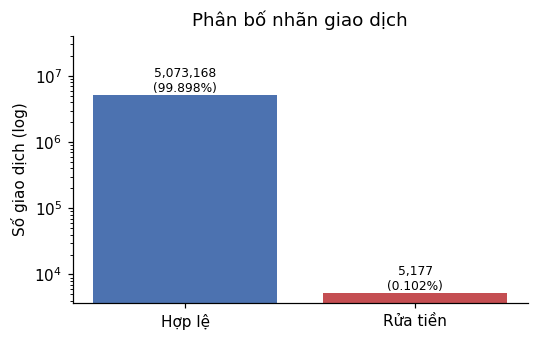

Cứ khoảng 981 giao dịch thì có 1 giao dịch rửa tiền.


,is_laundering,n,share_pct
0,0,5073168,99.898057
1,1,5177,0.101943


In [5]:
bal = q(f"SELECT is_laundering, count(*) AS n FROM {P} GROUP BY 1 ORDER BY 1")
bal["share_pct"] = 100 * bal.n / bal.n.sum()
bal.to_csv(TAB / "eda_class_balance.csv", index=False)
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar([LABELS[0], LABELS[1]], bal.n, color=[LICIT, ILLICIT])
ax.set_yscale("log"); ax.set_ylabel("Số giao dịch (log)")
for i, r in bal.iterrows():
    ax.text(i, r.n, f"{int(r.n):,}\n({r.share_pct:.3f}%)", ha="center", va="bottom", fontsize=8)
ax.set_ylim(top=bal.n.max() * 8); ax.set_title("Phân bố nhãn giao dịch")
save(fig, "eda_class_balance")
print(f"Cứ khoảng {bal.n.sum() / bal.n.iloc[1]:,.0f} giao dịch thì có 1 giao dịch rửa tiền.")
bal

## 3. Định dạng thanh toán và tiền tệ

### 3.1 Tỷ lệ rửa tiền theo định dạng thanh toán và theo tiền tệ thanh toán

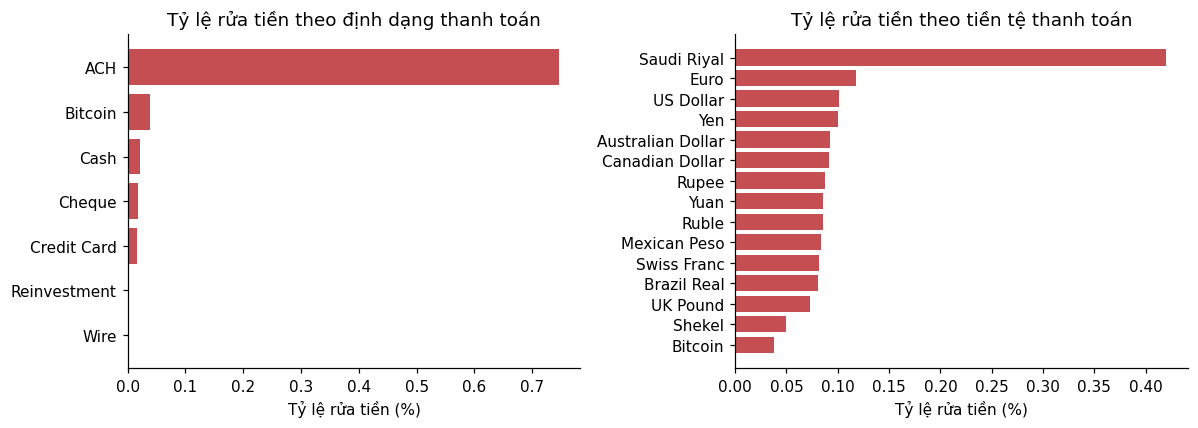

ACH: 11.8% số giao dịch, 86.6% số giao dịch rửa tiền, tỷ lệ 0.746% (gấp 7.3 lần mức nền).


,grp,n,ill,rate_pct
0,ACH,600797,4483.0,0.746175
1,Bitcoin,146091,56.0,0.038332
2,Cash,490891,108.0,0.022001
3,Cheque,1864331,324.0,0.017379
4,Credit Card,1323324,206.0,0.015567
5,Reinvestment,481056,0.0,0.000000
6,Wire,171855,0.0,0.000000


,grp,n,ill,rate_pct
0,Saudi Riyal,89014,374.0,0.420159
1,Euro,1168297,1372.0,0.117436
2,US Dollar,1895172,1912.0,0.100888
3,Yen,155209,155.0,0.099865
4,Australian Dollar,136769,127.0,0.092857
5,Canadian Dollar,140042,128.0,0.091401
6,Rupee,190202,167.0,0.087801
7,Yuan,213752,184.0,0.086081
8,Ruble,155178,133.0,0.085708
9,Mexican Peso,110159,92.0,0.083516


In [6]:
by_fmt = q(f"""SELECT payment_format AS grp, count(*) n, sum(is_laundering) ill,
               100.0*avg(is_laundering) AS rate_pct FROM {P} GROUP BY 1 ORDER BY rate_pct DESC""")
by_ccy = q(f"""SELECT pay_ccy AS grp, count(*) n, sum(is_laundering) ill,
               100.0*avg(is_laundering) AS rate_pct FROM {P} GROUP BY 1 ORDER BY rate_pct DESC""")
by_fmt.to_csv(TAB / "eda_rate_by_format.csv", index=False)
by_ccy.to_csv(TAB / "eda_rate_by_currency.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, d, t in zip(axes, (by_fmt, by_ccy), ("định dạng thanh toán", "tiền tệ thanh toán")):
    ax.barh(d.grp[::-1], d.rate_pct[::-1], color=ILLICIT)
    ax.set_xlabel("Tỷ lệ rửa tiền (%)"); ax.set_title(f"Tỷ lệ rửa tiền theo {t}")
save(fig, "eda_rate_by_format_currency")

ach = by_fmt.set_index("grp").loc["ACH"]
print(f"ACH: {ach.n / by_fmt.n.sum():.1%} số giao dịch, {ach.ill / by_fmt.ill.sum():.1%} số giao dịch rửa tiền, "
      f"tỷ lệ {ach.rate_pct:.3f}% (gấp {ach.rate_pct / (100 * by_fmt.ill.sum() / by_fmt.n.sum()):.1f} lần mức nền).")
display(by_fmt); display(by_ccy)

### 3.2 Giao dịch khác tiền tệ

Giao dịch có tiền tệ trả khác tiền tệ nhận. Trong HI-Small chúng hiếm và không có giao dịch rửa tiền nào như vậy. Nhưng các attempt rửa tiền thường đổi tiền tệ **giữa các chặng** (mục 6.2), nên khi so số tiền dọc một chuỗi phải quy về cùng một đơn vị (USD, mục 4.1).

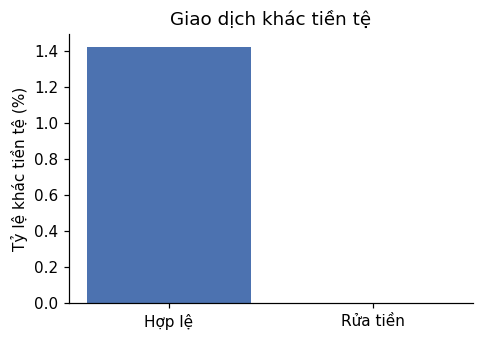

,is_laundering,n,xc,xc_pct
0,0,5073168,72170.0,1.422582
1,1,5177,0.0,0.000000


In [7]:
xc = q(f"""SELECT is_laundering, count(*) n, sum((pay_ccy<>recv_ccy)::INT) xc,
           100.0*avg((pay_ccy<>recv_ccy)::INT) AS xc_pct FROM {P} GROUP BY 1 ORDER BY 1""")
xc.to_csv(TAB / "eda_cross_currency.csv", index=False)
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar([LABELS[0], LABELS[1]], xc.xc_pct, color=[LICIT, ILLICIT])
ax.set_ylabel("Tỷ lệ khác tiền tệ (%)"); ax.set_title("Giao dịch khác tiền tệ")
save(fig, "eda_cross_currency")
xc

## 4. Số tiền

### 4.1 Tỷ giá và số tiền quy USD

Tỷ giá ước lượng ngay từ dữ liệu: với mỗi cặp tiền tệ, lấy trung vị của `amt_received / amt_paid` trên các giao dịch khác tiền tệ có số tiền trả từ 100 trở lên, rồi nối các cặp về USD (`chain_to_usd`). Kết quả ghi vào `fx_rates.csv` và được notebook 02 dùng lại.

Tứ phân vị và histogram tính trên **toàn bộ** giao dịch có số tiền dương (không lấy mẫu). Histogram dùng 79 khoảng chia đều theo log từ 0,01 đến 10¹¹ USD; trục tung là tỷ lệ % giao dịch của từng nhóm nhãn rơi vào mỗi khoảng, để so hình dạng hai nhóm dù cỡ rất khác nhau.

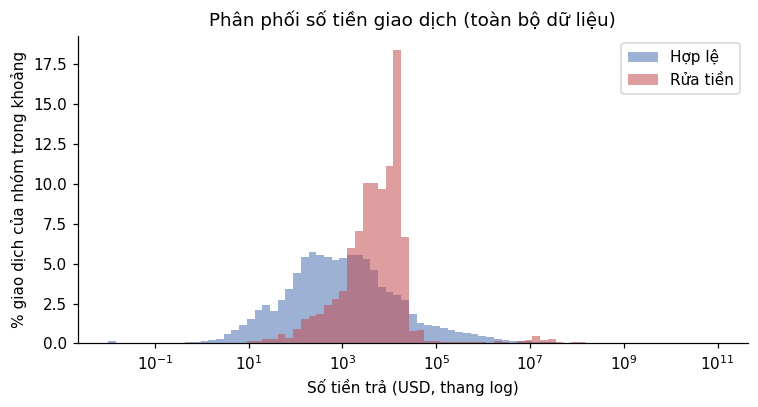

Trung vị nhóm rửa tiền gấp 6.6 lần nhóm hợp lệ.


,is_laundering,n,q1_usd,median_usd,q3_usd,p99_usd,max_usd
0,0,5073168,158.00,891.05,5273.84,3099715.32,2.655861e+10
1,1,5177,2160.56,5878.81,13758.50,15793198.25,1.629705e+10


In [8]:
prepare_usd_amounts()
db.execute("SELECT * FROM fx_rates").df().to_csv(TAB / "fx_rates.csv", index=False)

amount_summary = q("""
    SELECT is_laundering, count(*) AS n,
           quantile_cont(amt_usd, 0.25) AS q1_usd, median(amt_usd) AS median_usd,
           quantile_cont(amt_usd, 0.75) AS q3_usd, quantile_cont(amt_usd, 0.99) AS p99_usd,
           max(amt_usd) AS max_usd
    FROM transaction_amounts WHERE amt_usd > 0 GROUP BY 1 ORDER BY 1
""")
amount_summary.to_csv(TAB / "eda_amount_summary.csv", index=False)

LOG_LO, LOG_HI, N_BINS = -2.0, 11.0, 79
edges = np.logspace(LOG_LO, LOG_HI, N_BINS + 1)
hist = q(f"""
    SELECT is_laundering,
           least(greatest(floor((log10(amt_usd) - ({LOG_LO})) / {(LOG_HI - LOG_LO) / N_BINS}), 0), {N_BINS - 1})::INT AS b,
           count(*) AS n
    FROM transaction_amounts WHERE amt_usd > 0 GROUP BY 1, 2
""")
fig, ax = plt.subplots(figsize=(7, 3.8))
for lab, col in ((0, LICIT), (1, ILLICIT)):
    counts = np.zeros(N_BINS)
    part = hist[hist.is_laundering == lab]
    counts[part.b.to_numpy()] = part.n.to_numpy()
    ax.stairs(100 * counts / counts.sum(), edges, fill=True, alpha=0.55, color=col, label=LABELS[lab])
ax.set_xscale("log")
ax.set_xlabel("Số tiền trả (USD, thang log)"); ax.set_ylabel("% giao dịch của nhóm trong khoảng")
ax.legend(); ax.set_title("Phân phối số tiền giao dịch (toàn bộ dữ liệu)")
save(fig, "eda_amount_distribution")

med = amount_summary.set_index("is_laundering").median_usd
print(f"Trung vị nhóm rửa tiền gấp {med[1] / med[0]:.1f} lần nhóm hợp lệ.")
amount_summary.round(2)

### 4.2 Số tiền tròn

Số tiền tròn ở đây là bội số của 100 theo tiền tệ thanh toán. Đây là một dấu hiệu hay được nhắc trong tài liệu AML; bảng cho thấy trong HI-Small nó gần như không phân biệt hai nhóm, nên đề tài không dùng.

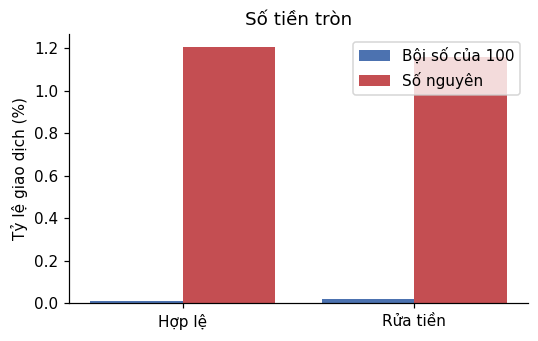

,is_laundering,round_pct,whole_pct
0,0,0.012339,1.206682
1,1,0.019316,1.158972


In [9]:
rnd = q(f"""SELECT is_laundering, 100.0*avg((amt_paid % 100 = 0)::INT) AS round_pct,
            100.0*avg((amt_paid % 1 = 0)::INT) AS whole_pct FROM {P} GROUP BY 1 ORDER BY 1""")
rnd.to_csv(TAB / "eda_round_amounts.csv", index=False)
fig, ax = plt.subplots(figsize=(5, 3.2))
x = np.arange(2)
ax.bar(x - 0.2, rnd.round_pct, 0.4, label="Bội số của 100", color=LICIT)
ax.bar(x + 0.2, rnd.whole_pct, 0.4, label="Số nguyên", color=ILLICIT)
ax.set_xticks(x, [LABELS[0], LABELS[1]]); ax.set_ylabel("Tỷ lệ giao dịch (%)")
ax.legend(); ax.set_title("Số tiền tròn")
save(fig, "eda_round_amounts")
rnd

## 5. Thời gian và cách chia dev / test

### 5.1 Hoạt động và tỷ lệ rửa tiền theo thời gian

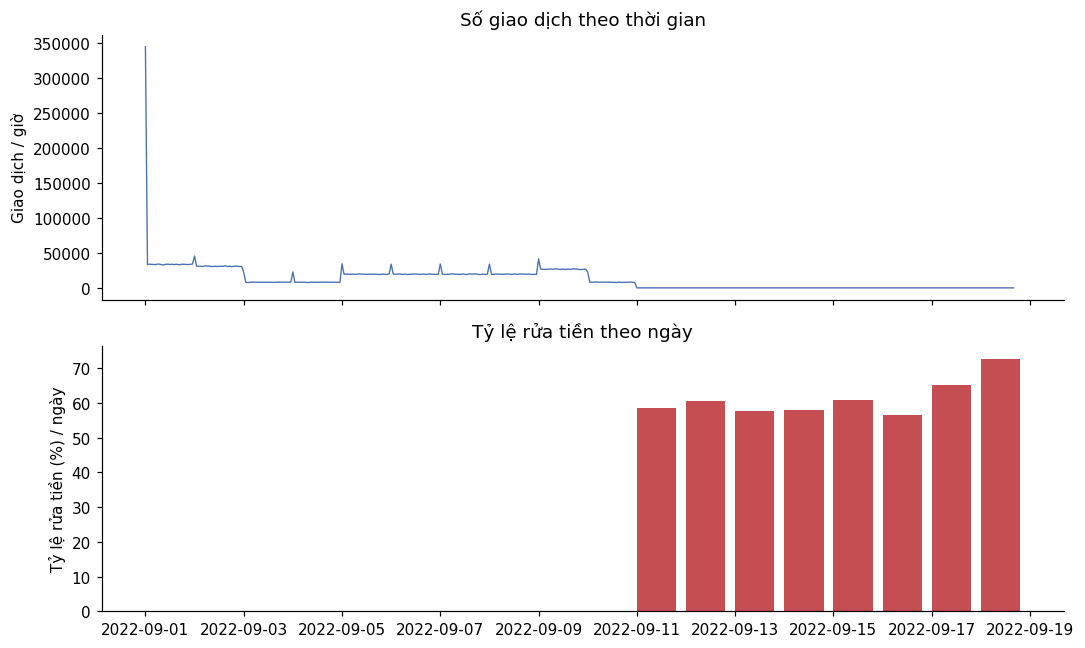

,d,n,ill,rate_pct
0,2022-09-01,1114921,322.0,0.028881
1,2022-09-02,754449,408.0,0.054079
2,2022-09-03,207382,391.0,0.188541
3,2022-09-04,207430,407.0,0.196211
4,2022-09-05,482650,471.0,0.097586
5,2022-09-06,482089,531.0,0.110146
6,2022-09-07,482751,497.0,0.102952
7,2022-09-08,482773,539.0,0.111647
8,2022-09-09,654467,514.0,0.078537
9,2022-09-10,208325,442.0,0.212168


In [10]:
hourly = q(f"""SELECT date_trunc('hour', timestamp) AS h, count(*) n FROM {P} GROUP BY 1 ORDER BY 1""")
daily = q(f"""SELECT date_trunc('day', timestamp) AS d, count(*) n, sum(is_laundering) ill,
              100.0*avg(is_laundering) AS rate_pct FROM {P} GROUP BY 1 ORDER BY 1""")
daily.to_csv(TAB / "eda_daily.csv", index=False)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(hourly.h, hourly.n, color=LICIT, lw=0.9); axes[0].set_ylabel("Giao dịch / giờ")
axes[0].set_title("Số giao dịch theo thời gian")
axes[1].bar(daily.d, daily.rate_pct, width=0.8, color=ILLICIT, align="edge")
axes[1].set_ylabel("Tỷ lệ rửa tiền (%) / ngày"); axes[1].set_title("Tỷ lệ rửa tiền theo ngày")
save(fig, "eda_activity_over_time")
daily

### 5.2 Đuôi dữ liệu và kỳ phân tích

Bảng `daily` cho thấy mấy ngày cuối có rất ít giao dịch nhưng tỷ lệ rửa tiền rất cao. Đây là đặc điểm của bộ mô phỏng: các attempt bắt đầu trước khi dữ liệu nền dừng vẫn chạy nốt. Mọi cửa sổ thời gian kết thúc trong đuôi sẽ gần như toàn giao dịch rửa tiền, nên giữ đuôi trong tập đánh giá sẽ làm kết quả đẹp giả.

Hiện tượng được nhận ra khi xem bảng có nhãn, nhưng **quy tắc cắt chỉ dùng số giao dịch**, không dùng nhãn:
1. **Đuôi** bắt đầu từ ngày đầu tiên mà ngày đó và mọi ngày sau đều có số giao dịch dưới 5% trung vị số giao dịch/ngày.
2. **Kỳ chính** = từ đầu dữ liệu đến trước đuôi.
3. **dev** = 60% số giao dịch đầu tiên của kỳ chính, làm tròn xuống đầu giờ; **test** = phần còn lại. dev dùng để chọn biến thể và tham số; test chỉ dùng để báo cáo, một lần.
4. Đuôi không dùng để chọn gì; chỉ báo cáo riêng như kiểm tra độ nhạy.

Các mốc ghi vào `reports/tables/analysis_period.json`, theo dạng nửa khoảng `[start, end)`. Notebook 02–04 đọc file này.

In [11]:
TAIL_SHARE_OF_MEDIAN = 0.05
DEV_SHARE = 0.60

day_counts = daily[["d", "n"]].sort_values("d").reset_index(drop=True)
low = day_counts.n < TAIL_SHARE_OF_MEDIAN * day_counts.n.median()
tail_from = len(day_counts)
for i in range(len(day_counts) - 1, -1, -1):
    if not low.iloc[i]:
        break
    tail_from = i
main_start = pd.Timestamp(scale.first_ts.iloc[0]).floor("D")
data_end = pd.Timestamp(scale.last_ts.iloc[0]) + pd.Timedelta(minutes=1)   # exclusive
main_end = pd.Timestamp(day_counts.d.iloc[tail_from]) if tail_from < len(day_counts) else data_end

cut = db.execute(f"""
    SELECT quantile_disc(timestamp, {DEV_SHARE}) FROM {P}
    WHERE timestamp >= ? AND timestamp < ?
""", [main_start, main_end]).fetchone()[0]
dev_end = pd.Timestamp(cut).floor("h")

period = {
    "main_start": str(main_start), "dev_end": str(dev_end),
    "main_end": str(main_end), "data_end": str(data_end),
    "rule": (f"tail = trailing days with < {TAIL_SHARE_OF_MEDIAN:.0%} of the median daily count; "
             f"dev = first {DEV_SHARE:.0%} of main-period transactions, floored to the hour; "
             "intervals are [start, end)"),
    "source_rows": int(n_rows),
}
with open(TAB / "analysis_period.json", "w", encoding="utf-8") as fh:
    json.dump(period, fh, indent=2)

segments = q(f"""
    SELECT CASE WHEN timestamp < TIMESTAMP '{dev_end}' THEN '1_dev'
                WHEN timestamp < TIMESTAMP '{main_end}' THEN '2_test'
                ELSE '3_tail' END AS segment,
           min(timestamp) AS first_ts, max(timestamp) AS last_ts,
           count(*) AS n, sum(is_laundering) AS ill,
           100.0 * avg(is_laundering) AS rate_pct
    FROM {P} GROUP BY 1 ORDER BY 1
""")
segments["share_of_laundering_pct"] = 100 * segments.ill / segments.ill.sum()
segments.to_csv(TAB / "eda_segments.csv", index=False)
print(json.dumps(period, indent=2))
display(segments)

{
  "main_start": "2022-09-01 00:00:00",
  "dev_end": "2022-09-06 13:00:00",
  "main_end": "2022-09-11 00:00:00",
  "data_end": "2022-09-18 16:19:00",
  "rule": "tail = trailing days with < 5% of the median daily count; dev = first 60% of main-period transactions, floored to the hour; intervals are [start, end)",
  "source_rows": 5078345
}


,segment,first_ts,last_ts,n,ill,rate_pct,share_of_laundering_pct
0,1_dev,2022-09-01 00:00:00,2022-09-06 12:59:00,3035199,2272.0,0.074855,43.886421
1,2_test,2022-09-06 13:00:00,2022-09-10 23:59:00,2042038,2250.0,0.110184,43.461464
2,3_tail,2022-09-11 00:05:00,2022-09-18 16:18:00,1108,655.0,59.115523,12.652115


## 6. Self-loop và các kiểu rửa tiền

### 6.1 Self-loop

Self-loop là giao dịch có tài khoản gửi trùng tài khoản nhận (cùng mã ngân hàng dạng số, cùng số tài khoản). Phần lớn là Reinvestment. Chúng không tạo cạnh giữa hai tài khoản nên bị loại khỏi đồ thị ở mục 7, nhưng vẫn nằm trong mẫu số khi tính baseline và recall.

In [12]:
sl = q(f"""SELECT is_laundering, sum(is_self_loop::INT) AS self_loops, count(*) n,
           sum(is_self_loop::INT) FILTER (WHERE payment_format='Reinvestment') AS reinvestment
           FROM {P} GROUP BY 1 ORDER BY 1""")
sl.to_csv(TAB / "eda_self_loops.csv", index=False)
sl

,is_laundering,self_loops,n,reinvestment
0,0,591201.0,5073168,481056.0
1,1,11.0,5177,NaN


### 6.2 Các kiểu rửa tiền trong `HI-Small_Patterns.txt`

File liệt kê từng lần rửa tiền (*attempt*) theo 8 kiểu, mỗi attempt gồm nhiều giao dịch. Mỗi dòng pattern được ghép với giao dịch rửa tiền trong file chính theo 10 trường (trừ nhãn). File này **chỉ dùng để mô tả và chấm điểm**, không dùng để dựng đồ thị hay quy tắc.

Ô dưới ghi bốn bảng:
- `eda_typologies.csv`: số attempt và số giao dịch theo kiểu;
- `eda_pattern_formats.csv`: định dạng thanh toán của giao dịch trong pattern, và số attempt đổi tiền tệ giữa các chặng;
- `eda_pattern_coverage.csv`: trong các giao dịch rửa tiền, bao nhiêu thuộc một attempt, tách theo định dạng;
- `eda_attempts_by_segment.csv`: attempt theo đoạn dev / test / đuôi (theo giao dịch cuối cùng), và số attempt nằm trọn trong một đoạn.

Ghép được 3,209/3,209 dòng pattern; 3,209/5,177 giao dịch rửa tiền (62.0%) thuộc một attempt.


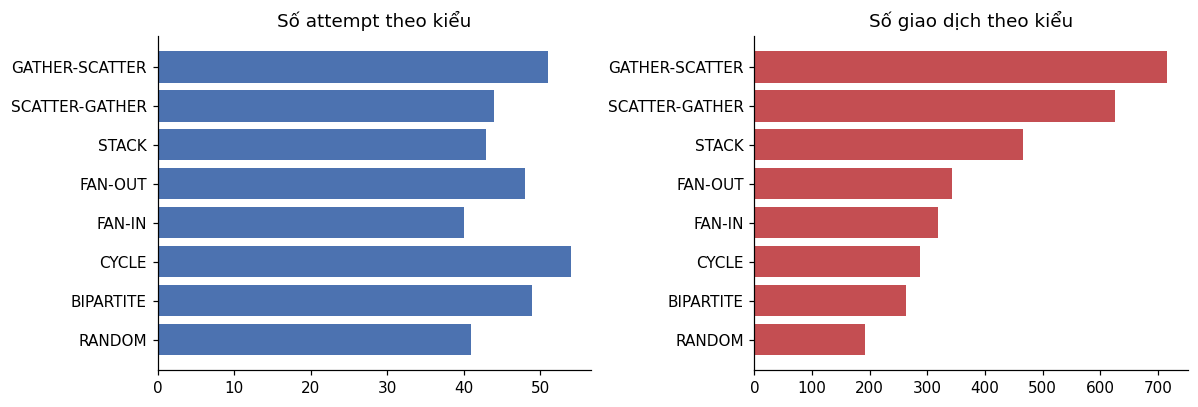

,attempts,transactions,txns_per_attempt
typology,,,
GATHER-SCATTER,51,716,14.039216
SCATTER-GATHER,44,626,14.227273
STACK,43,466,10.837209
FAN-OUT,48,342,7.125000
FAN-IN,40,318,7.950000
CYCLE,54,287,5.314815
BIPARTITE,49,263,5.367347
RANDOM,41,191,4.658537


Định dạng của giao dịch trong pattern: {'ACH': 3208, 'Bitcoin': 1}
Giao dịch khác tiền tệ trong pattern: 0; attempt đổi tiền tệ giữa các chặng: 216/370.


,attempts,all_ach,multi_currency
typology,,,
BIPARTITE,49,49,27
CYCLE,54,54,38
FAN-IN,40,40,0
FAN-OUT,48,48,33
GATHER-SCATTER,51,51,35
RANDOM,41,41,25
SCATTER-GATHER,44,44,29
STACK,43,42,29
Tổng,370,369,216


,payment_format,laundering_txns,in_attempt,not_in_attempt,in_attempt_pct
0,ACH,4483,3208,1275,71.559224
1,Cheque,324,0,324,0.000000
2,Credit Card,206,0,206,0.000000
3,Cash,108,0,108,0.000000
4,Bitcoin,56,1,55,1.785714


segment_end,dev,test,tail,within_one_segment
typology,,,,
BIPARTITE,22,18,9,40
CYCLE,18,25,11,28
FAN-IN,9,18,13,15
FAN-OUT,16,20,12,27
GATHER-SCATTER,8,16,27,10
RANDOM,11,21,9,23
SCATTER-GATHER,9,19,16,13
STACK,8,23,12,22
Tổng,101,160,109,178


In [13]:
if patterns_path is None:
    print("Không thấy HI-Small_Patterns.txt. Đặt HI_SMALL_PATTERNS để chạy mục này.")
else:
    patterns = parse_patterns(patterns_path)
    columns = ", ".join(KEY_COLUMNS)
    illicit_transactions = q(f"SELECT txn_id, is_laundering, {columns} FROM {P} WHERE is_laundering = 1")
    pat = match_to_transactions(patterns, illicit_transactions)

    # Kiểu rửa tiền
    typ = pat.groupby("typology").agg(attempts=("attempt_id", "nunique"), transactions=("seq", "size"))
    typ["txns_per_attempt"] = typ.transactions / typ.attempts
    typ = typ.sort_values("transactions", ascending=False)
    typ.to_csv(TAB / "eda_typologies.csv")
    n_ill = int(bal.loc[bal.is_laundering == 1, "n"].iloc[0])
    covered = pat.txn_id.nunique()
    print(f"Ghép được {pat.txn_id.notna().sum():,}/{len(pat):,} dòng pattern; "
          f"{covered:,}/{n_ill:,} giao dịch rửa tiền ({covered / n_ill:.1%}) thuộc một attempt.")
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].barh(typ.index[::-1], typ.attempts[::-1], color=LICIT); axes[0].set_title("Số attempt theo kiểu")
    axes[1].barh(typ.index[::-1], typ.transactions[::-1], color=ILLICIT)
    axes[1].set_title("Số giao dịch theo kiểu")
    save(fig, "eda_typologies")
    display(typ)

    # Định dạng và tiền tệ trong mỗi attempt
    per_attempt = pat.groupby("attempt_id").agg(
        typology=("typology", "first"), n_formats=("payment_format", "nunique"),
        n_currencies=("pay_ccy", "nunique"), all_ach=("payment_format", lambda s: (s == "ACH").all()))
    pattern_formats = per_attempt.groupby("typology").agg(
        attempts=("n_formats", "size"), all_ach=("all_ach", "sum"),
        multi_currency=("n_currencies", lambda s: int((s > 1).sum())))
    pattern_formats.loc["Tổng"] = pattern_formats.sum()
    pattern_formats.to_csv(TAB / "eda_pattern_formats.csv")
    print("Định dạng của giao dịch trong pattern:", pat.payment_format.value_counts().to_dict())
    print(f"Giao dịch khác tiền tệ trong pattern: {(pat.pay_ccy != pat.recv_ccy).sum()}; "
          f"attempt đổi tiền tệ giữa các chặng: {int((per_attempt.n_currencies > 1).sum())}/{len(per_attempt)}.")
    display(pattern_formats)

    # Độ phủ của pattern theo định dạng
    db.register("pattern_txn_ids", pd.DataFrame({"txn_id": pat.txn_id.dropna().astype("int64").unique()}))
    coverage = q(f"""
        SELECT payment_format,
               count(*) AS laundering_txns,
               count(p.txn_id) AS in_attempt,
               count(*) - count(p.txn_id) AS not_in_attempt,
               100.0 * count(p.txn_id) / count(*) AS in_attempt_pct
        FROM {P} t LEFT JOIN pattern_txn_ids p USING (txn_id)
        WHERE t.is_laundering = 1 GROUP BY 1 ORDER BY laundering_txns DESC
    """)
    db.unregister("pattern_txn_ids")
    coverage.to_csv(TAB / "eda_pattern_coverage.csv", index=False)
    display(coverage)

    # Attempt theo đoạn
    seg_of = lambda ts: np.where(ts < pd.Timestamp(dev_end), "dev",
                                 np.where(ts < pd.Timestamp(main_end), "test", "tail"))
    span = pat.groupby("attempt_id").agg(typology=("typology", "first"),
                                         first_ts=("timestamp", "min"), last_ts=("timestamp", "max"))
    span["segment_end"] = seg_of(span.last_ts)
    span["within_one_segment"] = seg_of(span.first_ts) == span.segment_end
    by_seg = (span.pivot_table(index="typology", columns="segment_end", values="first_ts",
                               aggfunc="size", fill_value=0)
              .reindex(columns=["dev", "test", "tail"], fill_value=0))
    by_seg["within_one_segment"] = span.groupby("typology").within_one_segment.sum()
    by_seg.loc["Tổng"] = by_seg.sum()
    by_seg.to_csv(TAB / "eda_attempts_by_segment.csv")
    display(by_seg)

## 7. Tiền xử lý cho đồ thị

Hai bước, theo thứ tự:
1. **Bỏ self-loop.**
2. **Bỏ dòng trùng hoàn toàn**: các dòng giống nhau ở cả 10 trường (giữ nguyên chuỗi số tiền gốc), giữ lại dòng có `txn_id` nhỏ nhất. Nếu một nhóm trùng có nhãn mâu thuẫn, notebook dừng lại.

`transaction_id = txn_id + 1`, tức số thứ tự dòng dữ liệu trong CSV, đánh từ 1. Các dòng bị loại được ghi riêng kèm lý do để notebook 03–04 giữ đúng mẫu số khi đánh giá.

### 7.1 Bỏ self-loop

In [14]:
db.execute("""
    CREATE OR REPLACE TEMP VIEW non_self_loop_transactions AS
    SELECT *
    FROM transactions
    WHERE NOT is_self_loop
""")

non_loop_count = db.execute("""
    SELECT count(*) FROM non_self_loop_transactions
""").fetchone()[0]

print(f"Giao dịch gốc: {n_rows:,}")
print(f"Self-loop bị loại: {n_rows - non_loop_count:,}")
print(f"Còn lại sau khi bỏ self-loop: {non_loop_count:,}")

Giao dịch gốc: 5,078,345
Self-loop bị loại: 591,212
Còn lại sau khi bỏ self-loop: 4,487,133


### 7.2 Bỏ dòng trùng

In [15]:
db.execute("""
    CREATE OR REPLACE TEMP TABLE graph_rows AS
    SELECT min(txn_id) AS txn_id,
           count(*) AS group_size,
           min(is_laundering) <> max(is_laundering) AS label_conflict
    FROM non_self_loop_transactions
    GROUP BY timestamp, from_bank_id, from_acct, to_bank_id, to_acct,
             amt_received_raw, recv_ccy, amt_paid_raw, pay_ccy, payment_format
""")

graph_count, duplicates_removed, conflicts = db.execute("""
    SELECT count(*),
           coalesce(sum(group_size - 1), 0),
           count(*) FILTER (WHERE label_conflict)
    FROM graph_rows
""").fetchone()

if conflicts:
    raise ValueError(f"{conflicts:,} duplicate groups have conflicting labels.")
if not graph_count:
    raise ValueError("No transactions remain for graph analysis.")

print(f"Dòng trùng bị loại: {duplicates_removed:,}")
print(f"Giao dịch đưa vào đồ thị: {graph_count:,}")

Dòng trùng bị loại: 9
Giao dịch đưa vào đồ thị: 4,487,124


### 7.3 Ghi tập giao dịch cho đồ thị và tập đã loại

In [16]:
db.execute("""
    CREATE OR REPLACE TEMP VIEW graph_transactions AS
    SELECT t.txn_id + 1 AS transaction_id,
           t.timestamp, t.src, t.dst,
           t.from_bank, t.from_acct, t.to_bank, t.to_acct,
           t.from_bank_id, t.to_bank_id,
           t.amt_paid, t.pay_ccy, t.amt_paid_raw,
           t.amt_received, t.recv_ccy, t.amt_received_raw,
           t.payment_format, t.is_laundering
    FROM non_self_loop_transactions t
    JOIN graph_rows g USING (txn_id)
""")
# Các dòng không vào đồ thị. Notebook 03–04 vẫn giữ chúng trong mẫu số khi đánh giá.
db.execute("""
    CREATE OR REPLACE TEMP VIEW removed_transactions AS
    SELECT t.txn_id + 1 AS transaction_id, t.timestamp, t.src, t.dst,
           t.payment_format, t.is_laundering,
           CASE WHEN t.is_self_loop THEN 'self_loop' ELSE 'duplicate' END AS reason
    FROM transactions t
    LEFT JOIN graph_rows g USING (txn_id)
    WHERE g.txn_id IS NULL
""")

GRAPH_PATH = ROOT / "data" / "processed" / "hi_small_graph_transactions.parquet"
REMOVED_PATH = ROOT / "data" / "processed" / "hi_small_removed_transactions.parquet"
GRAPH_PATH.parent.mkdir(parents=True, exist_ok=True)

for view, target in (("graph_transactions", GRAPH_PATH), ("removed_transactions", REMOVED_PATH)):
    print(f"Đang ghi {target.name} ...", flush=True)
    try:
        target.unlink(missing_ok=True)
    except PermissionError:
        raise PermissionError(f"{target} đang bị notebook khác mở. Restart kernel của 02/03 rồi chạy lại ô này.")
    db.execute(f"COPY (SELECT * FROM {view}) TO ? (FORMAT PARQUET, COMPRESSION ZSTD)", [str(target)])

removed_summary = q("""SELECT reason, count(*) AS n, sum(is_laundering) AS laundering
                       FROM removed_transactions GROUP BY 1 ORDER BY 1""")
display(removed_summary)
print(f"Tập cho đồ thị: {GRAPH_PATH}")
print(f"Tập đã loại: {REMOVED_PATH}")

Đang ghi hi_small_graph_transactions.parquet ...
Đang ghi hi_small_removed_transactions.parquet ...


,reason,n,laundering
0,duplicate,9,0.0
1,self_loop,591212,11.0


Tập cho đồ thị: D:\KLTN\data\processed\hi_small_graph_transactions.parquet
Tập đã loại: D:\KLTN\data\processed\hi_small_removed_transactions.parquet


## 8. Baseline cấp giao dịch

Tính trên **file gốc** (`transactions`, gồm cả self-loop và dòng trùng) để mọi câu hỏi nghiên cứu dùng chung một mẫu số. Báo cho cả file, kỳ chính, và từng đoạn dev / test / đuôi.
- **Ngẫu nhiên (kỳ vọng)**: precision bằng tỷ lệ dương của đoạn.
- **ACH-only**: gắn cờ mọi giao dịch ACH.

Một quy tắc đồ thị chỉ có giá trị khi vượt cả hai baseline trên cùng tập và cùng đơn vị đánh giá.

In [17]:
def baseline_rows(label, where):
    n, n_positive, n_ach, tp_ach = db.execute(f"""
        SELECT count(*),
               count(*) FILTER (WHERE is_laundering = 1),
               count(*) FILTER (WHERE payment_format = 'ACH'),
               count(*) FILTER (WHERE payment_format = 'ACH' AND is_laundering = 1)
        FROM transactions WHERE {where}
    """).fetchone()
    random_precision = n_positive / n if n else np.nan
    ach_precision = tp_ach / n_ach if n_ach else np.nan
    return [
        {"period": label, "baseline": "Random (expected)", "n_transactions": n, "n_laundering": n_positive,
         "n_flagged": pd.NA, "n_laundering_flagged": pd.NA,
         "precision_pct": 100 * random_precision, "recall_pct": np.nan, "lift_vs_random": 1.0},
        {"period": label, "baseline": "ACH-only", "n_transactions": n, "n_laundering": n_positive,
         "n_flagged": n_ach, "n_laundering_flagged": tp_ach,
         "precision_pct": 100 * ach_precision,
         "recall_pct": 100 * tp_ach / n_positive if n_positive else np.nan,
         "lift_vs_random": ach_precision / random_precision if random_precision else np.nan},
    ]

rows = []
for label, where in (
    ("all", "TRUE"),
    ("main", f"timestamp >= TIMESTAMP '{main_start}' AND timestamp < TIMESTAMP '{main_end}'"),
    ("dev", f"timestamp >= TIMESTAMP '{main_start}' AND timestamp < TIMESTAMP '{dev_end}'"),
    ("test", f"timestamp >= TIMESTAMP '{dev_end}' AND timestamp < TIMESTAMP '{main_end}'"),
    ("tail", f"timestamp >= TIMESTAMP '{main_end}'"),
):
    rows += baseline_rows(label, where)
baselines = pd.DataFrame(rows)
baselines.to_csv(TAB / "eda_transaction_baselines.csv", index=False)
display(baselines.round(4))

,period,baseline,n_transactions,n_laundering,n_flagged,n_laundering_flagged,precision_pct,recall_pct,lift_vs_random
0,all,Random (expected),5078345,5177,<NA>,<NA>,0.1019,NaN,1.0000
1,all,ACH-only,5078345,5177,600797,4483,0.7462,86.5946,7.3196
2,main,Random (expected),5077237,4522,<NA>,<NA>,0.0891,NaN,1.0000
3,main,ACH-only,5077237,4522,599689,3828,0.6383,84.6528,7.1671
4,dev,Random (expected),3035199,2272,<NA>,<NA>,0.0749,NaN,1.0000
5,dev,ACH-only,3035199,2272,337203,1882,0.5581,82.8345,7.4560
6,test,Random (expected),2042038,2250,<NA>,<NA>,0.1102,NaN,1.0000
7,test,ACH-only,2042038,2250,262486,1946,0.7414,86.4889,6.7285
8,tail,Random (expected),1108,655,<NA>,<NA>,59.1155,NaN,1.0000
9,tail,ACH-only,1108,655,1108,655,59.1155,100.0000,1.0000


## 9. Bảng số liệu chính

Gom các con số được trích trong README và khóa luận vào một file, `eda_key_numbers.csv`. Khi viết, chỉ chép số từ file này (hoặc từ các bảng gốc ở trên), không gõ tay.

In [18]:
def pct(a, b):
    return 100 * a / b if b else np.nan

ach_row = by_fmt.set_index("grp").loc["ACH"]
seg = segments.set_index("segment")
bl = baselines.set_index(["period", "baseline"])
key_numbers = [
    ("transactions_raw", n_rows, "Giao dịch trong CSV gốc"),
    ("accounts_raw", int(scale.accounts.iloc[0]), "Tài khoản (khóa số) trong CSV gốc"),
    ("bank_codes_string", int(bank_check.distinct_bank_strings.iloc[0]), "Mã ngân hàng dạng chuỗi"),
    ("banks_raw", int(scale.banks.iloc[0]), "Ngân hàng sau khi gộp số 0 đầu"),
    ("span_days", round(float(scale.span_days.iloc[0]), 2), "Số ngày quan sát"),
    ("laundering_txns", int(bal.n.iloc[1]), "Giao dịch rửa tiền"),
    ("laundering_rate_pct", round(float(bal.share_pct.iloc[1]), 4), "Tỷ lệ rửa tiền (%)"),
    ("ach_share_of_txns_pct", round(pct(ach_row.n, by_fmt.n.sum()), 2), "ACH / tổng giao dịch (%)"),
    ("ach_share_of_laundering_pct", round(pct(ach_row.ill, by_fmt.ill.sum()), 2), "ACH / giao dịch rửa tiền (%)"),
    ("self_loops", int(n_rows - non_loop_count), "Self-loop bị loại"),
    ("duplicates_removed", int(duplicates_removed), "Dòng trùng bị loại"),
    ("graph_transactions", int(graph_count), "Giao dịch đưa vào đồ thị"),
    ("dev_end", str(dev_end), "Mốc dev / test"),
    ("main_end", str(main_end), "Mốc test / đuôi"),
]
for s, name in (("1_dev", "dev"), ("2_test", "test"), ("3_tail", "tail")):
    if s in seg.index:
        key_numbers += [(f"{name}_txns", int(seg.loc[s, "n"]), f"Giao dịch đoạn {name}"),
                        (f"{name}_laundering", int(seg.loc[s, "ill"]), f"Giao dịch rửa tiền đoạn {name}")]
for period_name in ("all", "test"):
    key_numbers += [
        (f"{period_name}_random_precision_pct", round(float(bl.loc[(period_name, "Random (expected)"), "precision_pct"]), 4),
         f"Baseline ngẫu nhiên, {period_name} (%)"),
        (f"{period_name}_ach_alerts", int(bl.loc[(period_name, "ACH-only"), "n_flagged"]), f"ACH-only: số cảnh báo, {period_name}"),
        (f"{period_name}_ach_precision_pct", round(float(bl.loc[(period_name, "ACH-only"), "precision_pct"]), 4),
         f"ACH-only: precision, {period_name} (%)"),
        (f"{period_name}_ach_recall_pct", round(float(bl.loc[(period_name, "ACH-only"), "recall_pct"]), 2),
         f"ACH-only: recall, {period_name} (%)"),
    ]
if patterns_path is not None:
    key_numbers += [("pattern_attempts", int(typ.attempts.sum()), "Attempt trong Patterns.txt"),
                    ("pattern_txns", int(typ.transactions.sum()), "Giao dịch trong Patterns.txt"),
                    ("pattern_coverage_pct", round(100 * covered / n_ill, 2), "Giao dịch rửa tiền thuộc một attempt (%)")]
key_numbers = pd.DataFrame(key_numbers, columns=["key", "value", "description"])
key_numbers.to_csv(TAB / "eda_key_numbers.csv", index=False)
print(f"Đã ghi {len(key_numbers)} số vào {TAB / 'eda_key_numbers.csv'}")
key_numbers

Đã ghi 31 số vào D:\KLTN\reports\tables\eda_key_numbers.csv


,key,value,description
0,transactions_raw,5078345,Giao dịch trong CSV gốc
1,accounts_raw,515088,Tài khoản (khóa số) trong CSV gốc
2,bank_codes_string,30528,Mã ngân hàng dạng chuỗi
3,banks_raw,30470,Ngân hàng sau khi gộp số 0 đầu
4,span_days,17.68,Số ngày quan sát
5,laundering_txns,5177,Giao dịch rửa tiền
6,laundering_rate_pct,0.1019,Tỷ lệ rửa tiền (%)
7,ach_share_of_txns_pct,11.83,ACH / tổng giao dịch (%)
8,ach_share_of_laundering_pct,86.59,ACH / giao dịch rửa tiền (%)
9,self_loops,591212,Self-loop bị loại
